In [22]:
import tensorflow as tf
import keras
from keras import layers , models
from keras.models import Sequential
from keras.layers import (
Input , Rescaling , Conv2D , Flatten ,MaxPooling2D, Dense 
)

import matplotlib.pyplot as plt
from keras.applications import MobileNetV2

In [4]:
data_dir = "/kaggle/input/datasets/showravdhar/apple-disease-dataset/Apple_Disease_Dataset"
IMG_Size = (128,128)
Batch_size = 32

In [5]:
train_data  = tf.keras.utils.image_dataset_from_directory(
    f"{data_dir}/train",
    validation_split = 0.2,
    subset = "training",
seed = 42,
image_size = IMG_Size,
batch_size = Batch_size

)

Found 7771 files belonging to 4 classes.
Using 6217 files for training.


I0000 00:00:1793474121.729905     277 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793474121.732192     277 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [6]:
val_data  = tf.keras.utils.image_dataset_from_directory(
    f"{data_dir}/train",
    validation_split = 0.2,
    subset = "validation",
seed = 42,
image_size = IMG_Size,
batch_size = Batch_size

)

Found 7771 files belonging to 4 classes.
Using 1554 files for validation.


In [7]:
test_data = tf.keras.utils.image_dataset_from_directory(
    f"{data_dir}/test",
    image_size = IMG_Size,
    batch_size = Batch_size,
    shuffle = False
)

Found 1943 files belonging to 4 classes.


In [8]:
class_names = train_data.class_names
class_names

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy']

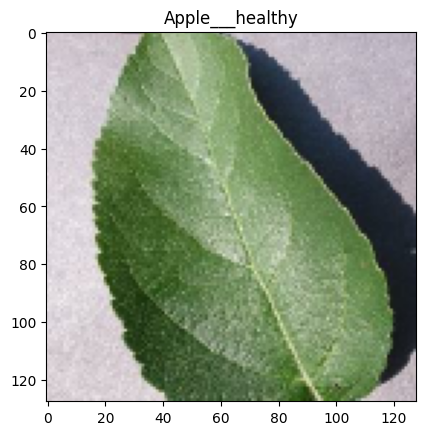

In [9]:
for image , label in train_data.take(1):
    image = image[0]
    label = label[0]
    label_number = label.numpy()
    label_name = class_names[label_number]
    plt.imshow(image.numpy().astype('uint8'))
    plt.title(label_name)

In [10]:
model = Sequential([
    Input(shape=(128,128 , 3)),
    Rescaling(1.0 / 255),
    Conv2D(32,kernel_size =3 , activation = "relu" ),
    MaxPooling2D(),
    Conv2D(32,kernel_size = 3 , activation = "relu"),
    MaxPooling2D(),
    Flatten(),
    Dense(128, activation ="relu"),
    Dense(4, activation = "softmax")
])

In [11]:
model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,686,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,697,188 (14.10 MB)

 Trainable params: 3,697,188 (14.10 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.fit(train_data , validation_data= val_data , epochs = 10)

Epoch 1/10


2026-10-31 19:15:40.062033: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 19:15:40.203369: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  1/195 ━━━━━━━━━━━━━━━━━━━━ 19:12 6s/step - accuracy: 0.1875 - loss: 1.3950

I0000 00:00:1793474141.718725     343 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


194/195 ━━━━━━━━━━━━━━━━━━━━ 0s 870ms/step - accuracy: 0.6586 - loss: 0.7953

2026-10-31 19:18:30.602247: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 19:18:30.743976: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 19:18:30.881659: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


195/195 ━━━━━━━━━━━━━━━━━━━━ 218s 1s/step - accuracy: 0.8065 - loss: 0.4907 - val_accuracy: 0.9299 - val_loss: 0.2333
Epoch 2/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9381 - loss: 0.1752 - val_accuracy: 0.9009 - val_loss: 0.3091
Epoch 3/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9599 - loss: 0.1160 - val_accuracy: 0.9144 - val_loss: 0.2570
Epoch 4/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9723 - loss: 0.0847 - val_accuracy: 0.9569 - val_loss: 0.1498
Epoch 5/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9723 - loss: 0.0795 - val_accuracy: 0.9492 - val_loss: 0.1600
Epoch 6/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9854 - loss: 0.0421 - val_accuracy: 0.9286 - val_loss: 0.2623
Epoch 7/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9876 - loss: 0.0346 - val_accuracy: 0.9459 - val_loss: 0.2126
Epoch 8/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9878 - loss: 0.0365 - val_accuracy: 0.946

In [14]:
loss , accuracy = model.evaluate(test_data)

61/61 ━━━━━━━━━━━━━━━━━━━━ 52s 849ms/step - accuracy: 0.9696 - loss: 0.0978


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Apple___Apple_scab
Apple___Apple_scab


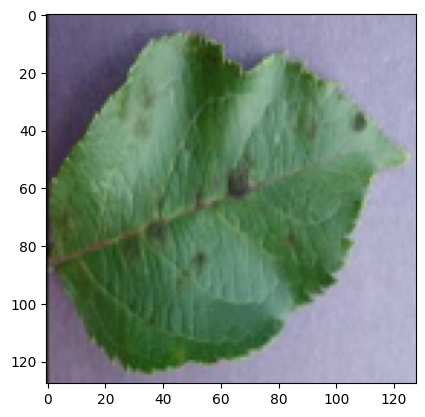

In [21]:
import numpy as np
for image , label in test_data.take(1):
    image = image[0]
    label = label[0].numpy()
    probabilites = model.predict(image.numpy().reshape(1,128,128,3))
    class_number = np.argmax(probabilites)
    actual_name = class_names[label]
    predicted_name = class_names[class_number]
    print(predicted_name)
    print(actual_name)
    plt.imshow(image.numpy().astype('uint8'))

In [23]:
base_model = MobileNetV2(
    input_shape = (128,128,3),
    include_top = False,
    weights = "imagenet"
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [24]:
base_model.trainable = False

In [32]:
model = Sequential([
    Input(shape=(128,128,3)),
    Rescaling(1.0/ 255),
    base_model , 
    MaxPooling2D(),
    Flatten(),
    Dense(128,activation = "relu"),
    Dense(4,activation = "softmax")
])

In [33]:
model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [34]:
model.fit(train_data , validation_data= val_data , epochs = 10)

Epoch 1/10


2026-10-31 19:33:01.948794: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 19:33:02.098637: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 19:33:02.236115: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


193/195 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8158 - loss: 0.9981

2026-10-31 19:33:15.665726: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 19:33:15.816401: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 19:33:15.953530: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


195/195 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.8169 - loss: 0.9914

2026-10-31 19:33:31.014060: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 19:33:31.151482: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 19:33:31.287349: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


195/195 ━━━━━━━━━━━━━━━━━━━━ 45s 148ms/step - accuracy: 0.9167 - loss: 0.3449 - val_accuracy: 0.9736 - val_loss: 0.0669
Epoch 2/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.9900 - loss: 0.0306 - val_accuracy: 0.9781 - val_loss: 0.0524
Epoch 3/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.9976 - loss: 0.0121 - val_accuracy: 0.9807 - val_loss: 0.0595
Epoch 4/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.9989 - loss: 0.0050 - val_accuracy: 0.9743 - val_loss: 0.0789
Epoch 5/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 0.9813 - val_loss: 0.0537
Epoch 6/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 1.0000 - loss: 9.4345e-04 - val_accuracy: 0.9833 - val_loss: 0.0537
Epoch 7/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 1.0000 - loss: 6.3760e-04 - val_accuracy: 0.9826 - val_loss: 0.0529
Epoch 8/10
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 1.0000 - loss: 4.9420e-04 - val_a